In [1]:
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.metrics import confusion_matrix, f1_score
from IPython.display import display


In [2]:

# ==========================================
# KONFIGURACJA
# ==========================================

THRESHOLDS = [0.00, 0.02, 0.05, 0.10, 0.15, 0.20]

TEST_YEARS = [2021, 2022, 2023, 2024]

CALIBRATION_YEARS = 3

OUTPUT = Path("wyniki_walk_forward_lppls_06")
OUTPUT.mkdir(exist_ok=True, parents=True)

candidates = [
    Path("wyniki_walidacji_lppls_04/lppls_daily_validation.csv"),
    Path("lppls_daily_validation.csv"),
]

file = next((p for p in candidates if p.exists()), None)

if file is None:
    raise FileNotFoundError(
        "Potrzebny jest plik lppls_daily_validation.csv "
        "z poprzedniego notatnika."
    )

daily = pd.read_csv(file)

if "date" not in daily.columns and "win_end" in daily.columns:
    daily = daily.rename(columns={"win_end": "date"})

needed = {"date", "confidence", "literature_bubble"}

assert needed.issubset(daily.columns), (
    f"Brak kolumn: {needed - set(daily.columns)}"
)

daily["date"] = pd.to_datetime(daily["date"]).dt.normalize()

daily["confidence"] = pd.to_numeric(
    daily["confidence"], errors="raise"
)

daily["literature_bubble"] = pd.to_numeric(
    daily["literature_bubble"], errors="raise"
).astype(int)

daily = daily.sort_values("date").reset_index(drop=True)

# ==========================================
# KONTROLA DANYCH
# ==========================================

assert daily["date"].is_unique, (
    "Każdy dzień powinien wystąpić tylko raz."
)

assert (
    daily["confidence"].notna().all()
    and daily["confidence"].between(0, 1).all()
)

assert daily["literature_bubble"].isin([0, 1]).all()

print(
    "Wczytano:", file,
    "| dni:", len(daily),
    "| zakres:", daily.date.min().date(),
    "–", daily.date.max().date()
)

print("Lata testowe:", TEST_YEARS)

display(daily.head())


Wczytano: wyniki_walidacji_lppls_04\lppls_daily_validation.csv | dni: 3624 | zakres: 2015-01-30 – 2024-12-31
Lata testowe: [2021, 2022, 2023, 2024]


,date,n_all,n_accepted,literature_bubble,confidence,lppls_alarm
0,2015-01-30,1,0,0,0.0,0
1,2015-01-31,1,0,0,0.0,0
2,2015-02-01,1,0,0,0.0,0
3,2015-02-02,1,0,0,0.0,0
4,2015-02-03,1,0,0,0.0,0


In [ ]:
data_union = [
    ["UNION01", "2016-06-08", "2016-06-18"],
    ["UNION02", "2016-12-30", "2017-01-15"],
    ["UNION03", "2017-02-22", "2017-03-07"],
    ["UNION04", "2017-04-27", "2017-07-05"],
    ["UNION05", "2017-07-15", "2018-01-09"],
    ["UNION06", "2019-06-17", "2019-07-13"],
    ["UNION07", "2019-08-09", "2019-08-10"],
    ["UNION08", "2019-12-06", "2020-01-05"],
    ["UNION09", "2020-02-07", "2020-02-17"],
    ["UNION10", "2020-03-20", "2020-09-21"],
    ["UNION11", "2020-11-06", "2021-05-20"],
    ["UNION12", "2021-08-08", "2021-09-19"],
    ["UNION13", "2021-10-05", "2021-12-02"],
    ["UNION14", "2024-03-04", "2024-03-25"],
]

episodes = pd.DataFrame(
    data_union,
    columns=["bubble_id", "start", "end"]
)

episodes[["start", "end"]] = episodes[
    ["start", "end"]
].apply(pd.to_datetime)

# Weryfikacja zgodności etykiet
reference = pd.Series(
    0, index=daily.index, dtype=int
)

for ep in episodes.itertuples(index=False):
    reference |= daily.date.between(
        ep.start, ep.end
    ).astype(int)

assert reference.eq(
    daily.literature_bubble
).all(), "Zapisane etykiety nie pasują do listy UNION."

print("Weryfikacja 14 epizodów: OK")

display(episodes)


Weryfikacja 14 epizodów: OK


,bubble_id,start,end
0,UNION01,2016-06-08,2016-06-18
1,UNION02,2016-12-30,2017-01-15
2,UNION03,2017-02-22,2017-03-07
3,UNION04,2017-04-27,2017-07-05
4,UNION05,2017-07-15,2018-01-09
5,UNION06,2019-06-17,2019-07-13
6,UNION07,2019-08-09,2019-08-10
7,UNION08,2019-12-06,2020-01-05
8,UNION09,2020-02-07,2020-02-17
9,UNION10,2020-03-20,2020-09-21


In [4]:

# ==========================================
# FUNKCJA OBLICZANIA METRYK
# ==========================================

def metrics(y_true, y_pred):

    y_true = np.asarray(y_true, dtype=int)
    y_pred = np.asarray(y_pred, dtype=int)

    tn, fp, fn, tp = confusion_matrix(
        y_true, y_pred, labels=[0, 1]
    ).ravel()

    positives = tp + fn
    negatives = tn + fp

    return {
        "n_days": len(y_true),
        "n_positive_days": int(positives),
        "alarm_days": int(y_pred.sum()),
        "TP": int(tp),
        "FP": int(fp),
        "FN": int(fn),
        "TN": int(tn),

        "precision": (
            tp / (tp + fp)
            if tp + fp else np.nan
        ),

        "recall": (
            tp / positives
            if positives else np.nan
        ),

        "specificity": (
            tn / negatives
            if negatives else np.nan
        ),

        "f1": (
            2 * tp / (2 * tp + fp + fn)
            if positives else np.nan
        ),

        "false_alarm_days": int(fp),
        "time_in_alarm": y_pred.mean()
    }


# ==========================================
# WALK-FORWARD
# ==========================================

selection_rows = []
fold_rows = []
pred_rows = []

for year in TEST_YEARS:

    # Trzy wcześniejsze lata
    calib = daily.loc[
        daily.date.dt.year.between(
            year - CALIBRATION_YEARS,
            year - 1
        )
    ].copy()

    # Rok testowy
    test = daily.loc[
        daily.date.dt.year.eq(year)
    ].copy()

    if calib.empty or test.empty:
        raise ValueError(
            f"Brakuje danych kalibracyjnych "
            f"lub testowych dla {year}"
        )

    assert calib.date.max() < test.date.min(), (
        "Błąd: kalibracja zawiera przyszłość"
    )

    # ======================================
    # WYBÓR PROGU NA KALIBRACJI
    # ======================================

    candidates = []

    for threshold in THRESHOLDS:

        pred_val = (
            calib.confidence > threshold
        ).astype(int)

        stat = metrics(
            calib.literature_bubble,
            pred_val
        )

        candidates.append({
            "test_year": year,
            "threshold": threshold,
            "calibration_f1": stat["f1"],
            "calibration_alarms": stat["alarm_days"],
            "calibration_positive_days": stat["n_positive_days"]
        })

    scores = pd.DataFrame(candidates)

    if scores["calibration_f1"].notna().sum() == 0:
        raise ValueError(
            f"Brak klasy pozytywnej w kalibracji "
            f"dla roku {year}: "
            f"nie można dobierać progu po F1."
        )

    # Największy F1; przy remisie mniej alarmów
    scores = scores.sort_values(
        ["calibration_f1", "calibration_alarms", "threshold"],
        ascending=[False, True, True],
        kind="mergesort"
    )

    best = float(scores.iloc[0]["threshold"])

    scores["chosen"] = scores["threshold"].eq(best)

    selection_rows.extend(
        scores.to_dict("records")
    )

    # ======================================
    # TEST WYBRANEGO PROGU
    # ORAZ DWÓCH PROGÓW STAŁYCH
    # ======================================

    strategies = [
        ("walk_forward_F1", best),
        ("fixed_0", 0.00),
        ("fixed_005", 0.05)
    ]

    for strategy, threshold in strategies:

        y_pred = (
            test.confidence > threshold
        ).astype(int)

        res = metrics(
            test.literature_bubble,
            y_pred
        )

        fold_rows.append({
            "year": year,
            "strategy": strategy,
            "threshold": threshold,
            "calibration_start": str(
                calib.date.min().date()
            ),
            "calibration_end": str(
                calib.date.max().date()
            ),
            **res
        })

        p = test[
            ["date", "literature_bubble", "confidence"]
        ].copy()

        p["test_year"] = year
        p["strategy"] = strategy
        p["threshold"] = threshold
        p["alarm"] = y_pred.values

        pred_rows.append(p)


# ==========================================
# ZBIORCZE WYNIKI
# ==========================================

selection = pd.DataFrame(selection_rows)
folds = pd.DataFrame(fold_rows)
predictions = pd.concat(
    pred_rows, ignore_index=True
)

print("Progi wybrane przez walk-forward:")

display(
    folds.loc[
        folds.strategy.eq("walk_forward_F1"),
        [
            "year",
            "threshold",
            "n_positive_days",
            "alarm_days",
            "TP",
            "FP",
            "FN",
            "TN",
            "precision",
            "recall",
            "f1"
        ]
    ].round(3)
)

# ==========================================
# ZAPIS
# ==========================================

selection.to_csv(
    OUTPUT / "01_kalibracja_progow.csv",
    index=False
)

folds.to_csv(
    OUTPUT / "02_wyniki_roczne.csv",
    index=False
)

predictions.to_csv(
    OUTPUT / "03_dzienne_predykcje_OOS.csv",
    index=False
)


Progi wybrane przez walk-forward:


,year,threshold,n_positive_days,alarm_days,TP,FP,FN,TN,precision,recall,f1
0,2021,0.0,242,95,94,1,148,122,0.989,0.388,0.558
3,2022,0.0,0,2,0,2,0,363,0.000,NaN,NaN
6,2023,0.0,0,64,0,64,0,301,0.000,NaN,NaN
9,2024,0.0,22,59,10,49,12,295,0.169,0.455,0.247


In [5]:

overall_rows = []

for strategy, part in predictions.groupby(
    "strategy", sort=False
):

    res = metrics(
        part.literature_bubble,
        part.alarm
    )

    overall_rows.append({
        "strategy": strategy,
        **res
    })

overall = pd.DataFrame(overall_rows)

print("Wyniki łączne OOS:")

display(overall.round(3))

overall.to_csv(
    OUTPUT / "04_wyniki_laczne_OOS.csv",
    index=False
)

print(
    "Uwaga: 'FP' = liczba dni fałszywego alarmu, "
    "nie liczba niezależnych epizodów alarmowych."
)


Wyniki łączne OOS:


,strategy,n_days,n_positive_days,alarm_days,TP,FP,FN,TN,precision,recall,specificity,f1,false_alarm_days,time_in_alarm
0,walk_forward_F1,1461,264,220,104,116,160,1081,0.473,0.394,0.903,0.430,116,0.151
1,fixed_0,1461,264,220,104,116,160,1081,0.473,0.394,0.903,0.430,116,0.151
2,fixed_005,1461,264,122,67,55,197,1142,0.549,0.254,0.954,0.347,55,0.084


Uwaga: 'FP' = liczba dni fałszywego alarmu, nie liczba niezależnych epizodów alarmowych.


In [6]:

episode_rows = []

for strategy, part in predictions.groupby(
    "strategy", sort=False
):

    part = part.sort_values("date")

    for ep in episodes.itertuples(index=False):

        # Pomijamy epizody, które nie są
        # w całości objęte okresem testowym
        if (
            ep.start < part.date.min()
            or ep.end > part.date.max()
        ):
            continue

        # ==================================
        # ALARMY W CZASIE BAŃKI
        # ==================================

        inside = part.date.between(
            ep.start, ep.end
        )

        window = part.loc[inside]

        alerts = window.loc[
            window.alarm.eq(1),
            "date"
        ]

        # ==================================
        # ALARMY PRZED POCZĄTKIEM BAŃKI
        # ==================================

        pre_start = ep.start - pd.Timedelta(
            days=30
        )

        before = part.loc[
            part.date.between(
                pre_start,
                ep.start - pd.Timedelta(days=1)
            )
        ]

        # Alarmy tylko poza innymi
        # epizodami referencyjnymi
        pre_alerts = before.loc[
            before.literature_bubble.eq(0)
            & before.alarm.eq(1),
            "date"
        ]

        episode_rows.append({
            "strategy": strategy,
            "bubble_id": ep.bubble_id,
            "start": str(ep.start.date()),
            "end": str(ep.end.date()),
            "n_days": len(window),
            "days_with_alarm": len(alerts),

            "coverage": (
                len(alerts) / len(window)
                if len(window) else np.nan
            ),

            "detected_any_day": bool(
                len(alerts)
            ),

            "detected_at_least_3_days": bool(
                len(alerts) >= 3
            ),

            "first_alarm_in_episode": (
                str(alerts.min().date())
                if len(alerts) else ""
            ),

            "prewarning_30d": bool(
                len(pre_alerts)
            ),

            "nearest_pre_alarm_date": (
                str(pre_alerts.max().date())
                if len(pre_alerts) else ""
            ),

            "days_before_start": (
                (ep.start - pre_alerts.max()).days
                if len(pre_alerts) else np.nan
            )
        })

# ==========================================
# ZAPIS WYNIKÓW EPIZODÓW
# ==========================================

episode_oos = pd.DataFrame(episode_rows)

print("Ocena epizodów w okresie testowym:")

display(episode_oos.round(3))

episode_oos.to_csv(
    OUTPUT / "05_epizody_OOS.csv",
    index=False
)


Ocena epizodów w okresie testowym:


,strategy,bubble_id,start,end,n_days,days_with_alarm,coverage,detected_any_day,detected_at_least_3_days,first_alarm_in_episode,prewarning_30d,nearest_pre_alarm_date,days_before_start
0,walk_forward_F1,UNION12,2021-08-08,2021-09-19,43,6,0.140,True,True,2021-08-08,True,2021-08-06,2.0
1,walk_forward_F1,UNION13,2021-10-05,2021-12-02,59,34,0.576,True,True,2021-10-18,False,,NaN
2,walk_forward_F1,UNION14,2024-03-04,2024-03-25,22,10,0.455,True,True,2024-03-05,True,2024-03-01,3.0
3,fixed_0,UNION12,2021-08-08,2021-09-19,43,6,0.140,True,True,2021-08-08,True,2021-08-06,2.0
4,fixed_0,UNION13,2021-10-05,2021-12-02,59,34,0.576,True,True,2021-10-18,False,,NaN
5,fixed_0,UNION14,2024-03-04,2024-03-25,22,10,0.455,True,True,2024-03-05,True,2024-03-01,3.0
6,fixed_005,UNION12,2021-08-08,2021-09-19,43,2,0.047,True,False,2021-08-14,False,,NaN
7,fixed_005,UNION13,2021-10-05,2021-12-02,59,26,0.441,True,True,2021-10-24,False,,NaN
8,fixed_005,UNION14,2024-03-04,2024-03-25,22,5,0.227,True,True,2024-03-05,False,,NaN


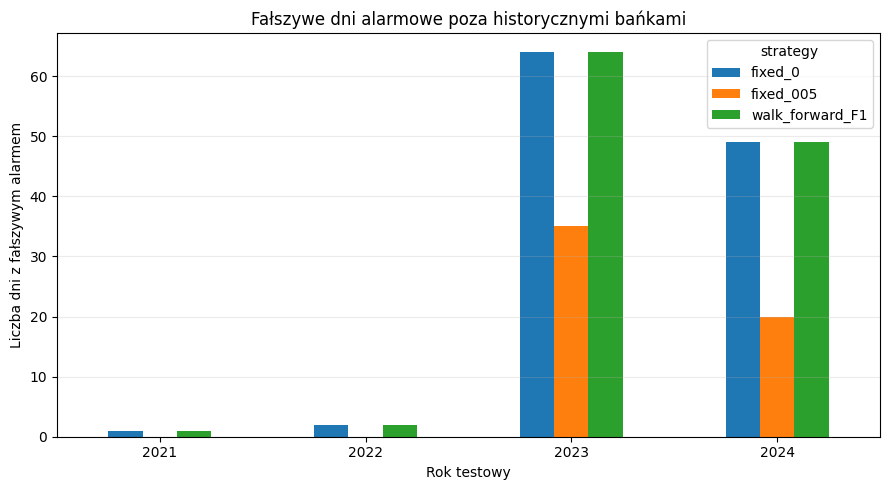

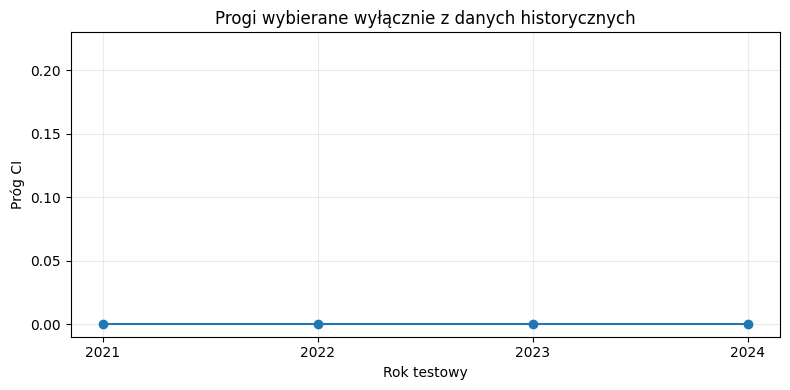

Wyniki zapisano w: C:\Users\cynar\Desktop\projects\lppls_article\wyniki_walk_forward_lppls_06


In [7]:

# ==========================================
# WYKRES 1. FAŁSZYWE ALARMY ROCZNIE
# ==========================================

piv = folds.pivot(
    index="year",
    columns="strategy",
    values="FP"
)

ax = piv.plot.bar(
    figsize=(9, 5),
    rot=0
)

ax.set_title(
    "Fałszywe dni alarmowe poza historycznymi bańkami"
)

ax.set_xlabel("Rok testowy")
ax.set_ylabel("Liczba dni z fałszywym alarmem")
ax.grid(axis="y", alpha=0.25)

plt.tight_layout()

plt.savefig(
    OUTPUT / "06_falszywe_alarmy_rocznie.png",
    dpi=180
)

plt.show()


# ==========================================
# WYKRES 2. PROGI WALK-FORWARD
# ==========================================

chosen = folds.loc[
    folds.strategy.eq("walk_forward_F1")
]

fig, ax = plt.subplots(figsize=(8, 4))

ax.plot(
    chosen.year,
    chosen.threshold,
    marker="o"
)

ax.set_xticks(TEST_YEARS)

ax.set_ylim(
    -0.01,
    max(THRESHOLDS) + 0.03
)

ax.set_ylabel("Próg CI")
ax.set_xlabel("Rok testowy")

ax.set_title(
    "Progi wybierane wyłącznie z danych historycznych"
)

ax.grid(alpha=0.25)

plt.tight_layout()

plt.savefig(
    OUTPUT / "07_progi_walk_forward.png",
    dpi=180
)

plt.show()

print(
    "Wyniki zapisano w:",
    OUTPUT.resolve()
)
